<a href="https://colab.research.google.com/github/GH-Rumi/PemMes_7_Helmi/blob/main/JS07/JS07_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Memuat dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

# Memisahkan fitur untuk klasterisasi (menghilangkan kolom identitas)
X = df.drop(['Sl_No', 'Customer Key'], axis=1)

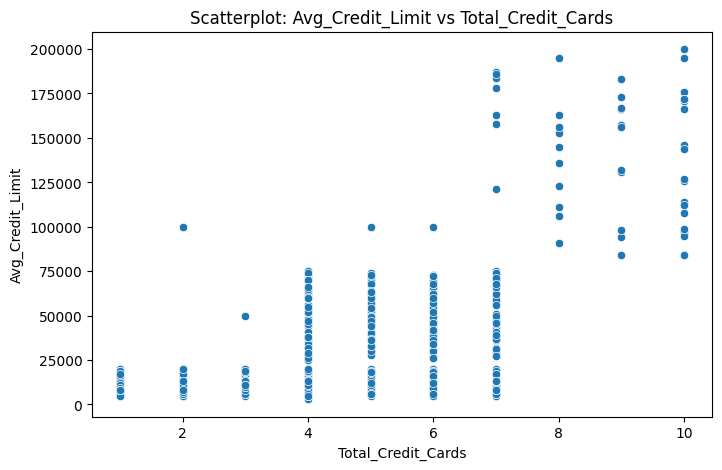

Korelasi: 0.609


In [2]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='Total_Credit_Cards', y='Avg_Credit_Limit')
plt.title('Scatterplot: Avg_Credit_Limit vs Total_Credit_Cards')
plt.show()

korelasi = df['Avg_Credit_Limit'].corr(df['Total_Credit_Cards'])
print(f"Korelasi: {korelasi:.3f}")

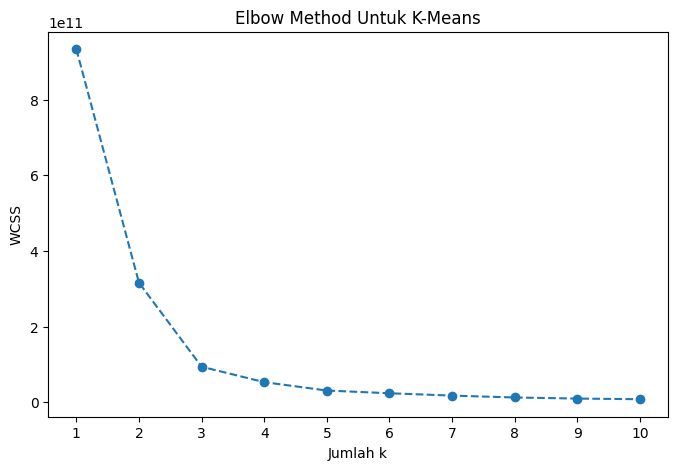

In [3]:
wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(K_range, wcss, marker='o', linestyle='--')
plt.title('Elbow Method Untuk K-Means')
plt.xlabel('Jumlah k')
plt.ylabel('WCSS')
plt.xticks(K_range)
plt.show()

# Menentukan k=3 berdasarkan elbow dan menyimpannya ke dataframe
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X)

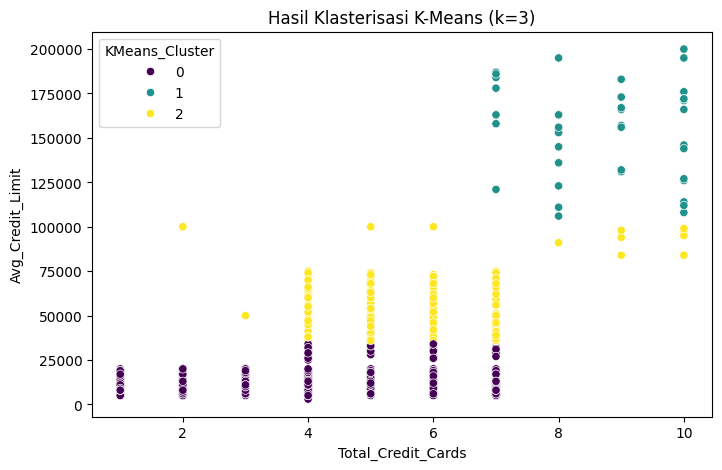

In [4]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='Total_Credit_Cards', y='Avg_Credit_Limit',
                hue='KMeans_Cluster', palette='viridis')
plt.title('Hasil Klasterisasi K-Means (k=3)')
plt.show()

In [5]:
# Standarisasi seluruh variabel sebelum memasukkannya ke algoritma jarak (DBSCAN)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

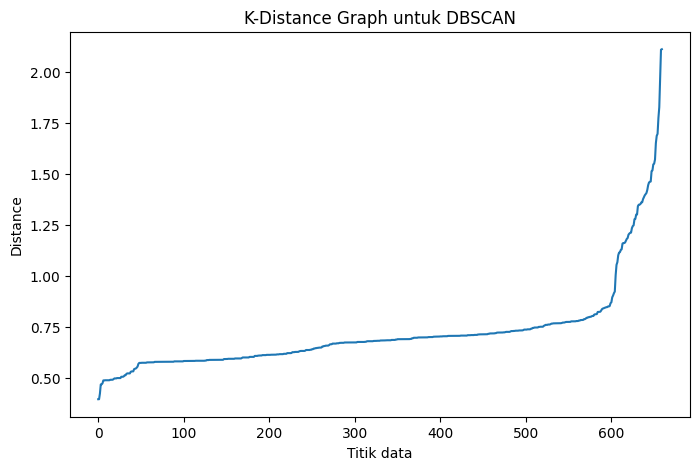

In [6]:
# Menentukan min_samples (2 * jumlah fitur)
min_samples = 2 * X.shape[1]

# Menghitung jarak ke tetangga terdekat (K-Distance)
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Mengurutkan jarak untuk menemukan "elbow"
distances = np.sort(distances[:, min_samples-1], axis=0)

plt.figure(figsize=(8,5))
plt.plot(distances)
plt.title('K-Distance Graph untuk DBSCAN')
plt.xlabel('Titik data')
plt.ylabel('Distance')
plt.show()

In [7]:
# Eksekusi DBSCAN dengan parameter terbaik dari grafik
best_eps = 1.20
dbscan = DBSCAN(eps=best_eps, min_samples=min_samples)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

# Menghitung metrik evaluasi
sil_score = silhouette_score(X_scaled, df['DBSCAN_Cluster'])
dbi_score = davies_bouldin_score(X_scaled, df['DBSCAN_Cluster'])

print(f"Silhouette Score : {sil_score:.4f}")
print(f"Davies-Bouldin Index : {dbi_score:.4f}")

Silhouette Score : 0.5246
Davies-Bouldin Index : 2.2526
